In [ ]:
###### This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk("./"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# 1. Frame the problem
Using the customer description, Define the problem your trying to solve in your own words (remember this is not technial but must be specific so the customer understands the project

The problem is figuring out a way to make a machine learning model play Tetris for a long time.

# 2. Get the Data 
Define how you recieved the data (provided, gathered..)

In [1]:
import sys

print(sys.version)
print(sys.executable)

# !{sys.executable} -m venv ~/tetris_env
# !~/tetris_env/bin/python -m pip install --upgrade pip
# !~/tetris_env/bin/python -m pip install ipykernel
# !~/tetris_env/bin/python -m ipykernel install --user --name=tetris_env --display-name="Python (Tetris)"
# !git clone https://gitlab.com/yukiman/tetris_a.git
# %cd tetris_a
# !ls -la
# !~/tetris_env/bin/python -m pip install -r requirements.txt
# !{sys.executable} -m pip install -r requirements.txt

3.12.6 | packaged by conda-forge | (main, Sep 22 2024, 14:16:49) [GCC 13.3.0]
/home/jupyter-250661/tetris_env/bin/python


In [3]:
!jupyter kernelspec list

Available kernels:
  tetris_env    /home/jupyter-250661/.local/share/jupyter/kernels/tetris_env
  python3       /opt/tljh/user/share/jupyter/kernels/python3


In [18]:
!pwd

/home/jupyter-250661/Project_6/tetris_a/src


# 3. Explore the Data
Gain insights into the data you have from step 2, making sure to identify any bias

A virtual environment for the Tetris game was created, in addition to a new kernel, Python (Tetris).

# 4.Prepare the Data


Apply any data transformations and explain what and why


In [9]:
import numpy as np
import random
import copy
import sys
#!{sys.executable} -m pip install matplotlib
import matplotlib.pyplot as plt
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim
from board import Board
from piece import Piece, BODIES

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

board = Board()
piece = Piece()

print("Board dimensions:", board.width, "x", board.height)
print("Piece body:", piece.body)
print("Piece skirt:", piece.skirt)

PyTorch: 2.15.0+cu132
CUDA available: False
Using device: cpu
Board dimensions: 10 x 20
Piece body: ((0, 0), (1, 0), (1, 1), (2, 0))
Piece skirt: [0, 0, 0]


/home/jupyter-250661/tetris_env/lib/python3.12/site-packages/torch/cuda/__init__.py:241: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [8]:
%cd src

/home/jupyter-250661/Project_6/tetris_a/src


# 5. Model the data
Using selected ML models, experment with your choices and describe your findings. Finish by selecting a Model to continue with


In [10]:
def get_state(board, piece):

    board_state = np.array(board.board, dtype=np.float32)
    piece_state = np.zeros((4, 4), dtype=np.float32)

    for x, y in piece.body:
        piece_state[y, x] = 1

    state = np.concatenate([board_state.flatten(), piece_state.flatten()])

    return state

def get_board_metrics(board):

    heights = board.heights
    aggregate_height = sum(heights)
    holes = 0

    for x in range(board.width):
        for y in range(heights[x]):
            if not board.board[y][x]:
                holes += 1

    bumpiness = sum(abs(heights[x] - heights[x + 1]) for x in range(board.width - 1))

    return aggregate_height, holes, bumpiness

class TetrisEnv:

    def __init__(self):

        self.width = 10
        self.height = 20
        self.board = None
        self.piece = None
        self.pieces_placed = 0
        self.rows_cleared = 0

    def reset(self):

        self.board = Board()
        self.piece = Piece()
        self.pieces_placed = 0
        self.rows_cleared = 0

        return get_state(self.board, self.piece)

    def get_rotations(self):

        rotations = []
        current = self.piece

        for _ in range(4):

            rotations.append(current)
            current = current.get_next_rotation()

        return rotations

    def valid_actions(self):

        valid = np.zeros(40, dtype=bool)
        rotations = self.get_rotations()

        for r, piece in enumerate(rotations):
            for x in range(self.width):
                if x + len(piece.skirt) > self.width:
                    continue

                y = self.board.drop_height(piece, x)

                if y < 0:
                    continue

                if y + max(pos[1] for pos in piece.body) >= self.board.height + 4:
                    continue

                collision = False

                for px, py in piece.body:
                    bx = x + px
                    by = y + py

                    if self.board.board[by][bx]:
                        collision = True
                        break

                if not collision:
                    action = r * 10 + x
                    valid[action] = True

        return valid

    def step(self, action):

        rotation = action // 10
        x = action % 10
        
        piece = self.get_rotations()[rotation]
        before_height, before_holes, before_bump = (get_board_metrics(self.board))
        y = self.board.drop_height(piece, x)
        result = self.board.place(x, y, piece)

        if isinstance(result, Exception):
            raise ValueError("Invalid Tetris placement")

        self.pieces_placed += 1

        lines = self.board.clear_rows()
        self.rows_cleared += lines
        after_height, after_holes, after_bump = (get_board_metrics(self.board))

        done = self.board.top_filled()

        reward = (
            10 * lines
            - 0.5 * (after_height - before_height)
            - 2.0 * (after_holes - before_holes)
            - 0.2 * (after_bump - before_bump)
        )

        if done:
            reward -= 50

        self.piece = Piece()

        next_state = get_state(self.board, self.piece)

        return next_state, reward, done

In [11]:
class DQN(nn.Module):

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 40))

    def forward(self, state):
        return self.network(state)

policy_net = DQN().to(device)
target_net = DQN().to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

print(policy_net)

DQN(
  (network): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=40, bias=True)
  )
)


In [12]:
class DQNAgent:

    def __init__(self):
        self.policy_net = DQN().to(device)
        self.target_net = DQN().to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=0.0001)
        self.memory = deque(maxlen=100000)
        self.batch_size = 128
        self.gamma = 0.99
        self.epsilon = 1.0
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995
        self.target_update = 1000
        self.steps = 0

    def select_action(self, state, valid_actions):

        possible_actions = np.flatnonzero(valid_actions)
        if len(possible_actions) == 0:
            raise ValueError("No valid actions available")

        if random.random() < self.epsilon:
            return int(random.choice(possible_actions))

        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

        with torch.no_grad():
            q_values = self.policy_net(state_tensor)
            mask = torch.tensor(valid_actions, dtype=torch.bool, device=device)
            q_values[0][~mask] = -float("inf")

            return int(q_values.argmax(dim=1).item())

    def remember(self, state, action, reward, next_state, done, next_mask):

        self.memory.append((
            np.array(state, dtype=np.float32),
            action,
            reward,
            np.array(next_state, dtype=np.float32),
            done,
            np.array(next_mask, dtype=bool)
        ))

    def train_step(self):

        if len(self.memory) < self.batch_size:
            return None

        batch = random.sample(self.memory,self.batch_size)
        states, actions, rewards, next_states, dones, masks = zip(*batch)
        
        states = torch.tensor(np.array(states), dtype=torch.float32, device=device)
        actions = torch.tensor(actions, dtype=torch.long, device=device).unsqueeze(1)
        rewards = torch.tensor(rewards, dtype=torch.float32, device=device)

        next_states = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        dones = torch.tensor(dones, dtype=torch.float32, device=device)
        masks = torch.tensor(np.array(masks), dtype=torch.bool, device=device)

        current_q = self.policy_net(states).gather(1, actions).squeeze(1)
        with torch.no_grad():
            next_q = self.target_net(next_states)
            next_q[~masks] = -1e9
            max_next_q = next_q.max(dim=1).values
            max_next_q[dones.bool()] = 0
            target_q = rewards + (self.gamma * max_next_q * (1 - dones))

        
        loss = nn.functional.smooth_l1_loss(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10)
        self.optimizer.step()

        self.steps += 1

        if self.steps % self.target_update == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())

        return loss.item()

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

Episode: 1/100 | Pieces: 17 | Lines: 0 | Reward: -273.70 | Epsilon: 0.995
Episode: 2/100 | Pieces: 17 | Lines: 0 | Reward: -268.00 | Epsilon: 0.990
Episode: 3/100 | Pieces: 20 | Lines: 0 | Reward: -262.20 | Epsilon: 0.985
Episode: 4/100 | Pieces: 25 | Lines: 0 | Reward: -271.00 | Epsilon: 0.980
Episode: 5/100 | Pieces: 18 | Lines: 0 | Reward: -252.40 | Epsilon: 0.975
Episode: 6/100 | Pieces: 16 | Lines: 0 | Reward: -256.90 | Epsilon: 0.970
Episode: 7/100 | Pieces: 21 | Lines: 0 | Reward: -253.80 | Epsilon: 0.966
Episode: 8/100 | Pieces: 20 | Lines: 0 | Reward: -277.90 | Epsilon: 0.961
Episode: 9/100 | Pieces: 19 | Lines: 0 | Reward: -242.00 | Epsilon: 0.956
Episode: 10/100 | Pieces: 21 | Lines: 0 | Reward: -269.10 | Epsilon: 0.951
Episode: 11/100 | Pieces: 24 | Lines: 0 | Reward: -238.80 | Epsilon: 0.946
Episode: 12/100 | Pieces: 22 | Lines: 0 | Reward: -310.40 | Epsilon: 0.942
Episode: 13/100 | Pieces: 25 | Lines: 0 | Reward: -261.00 | Epsilon: 0.937
Episode: 14/100 | Pieces: 25 | Lin

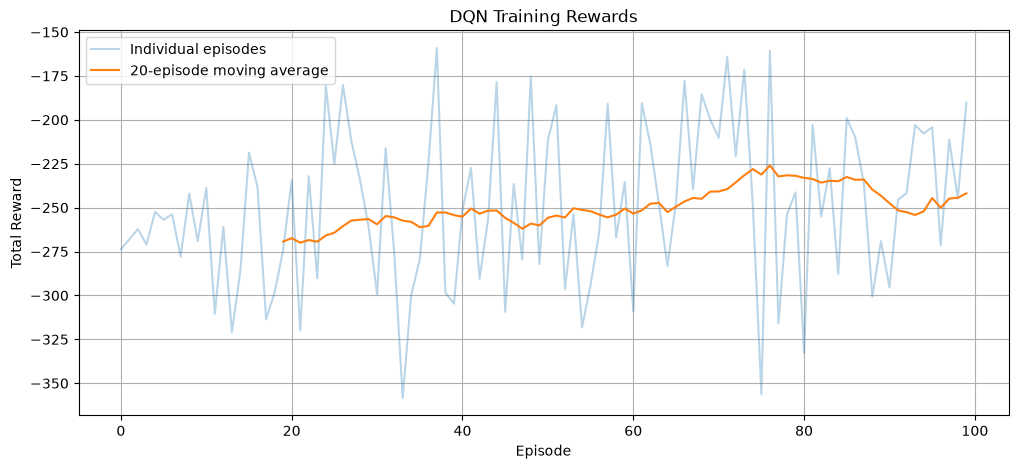

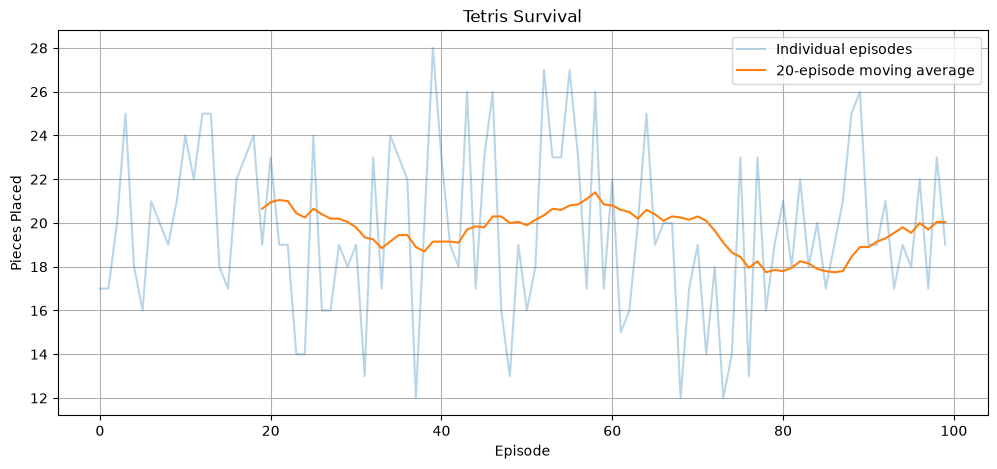

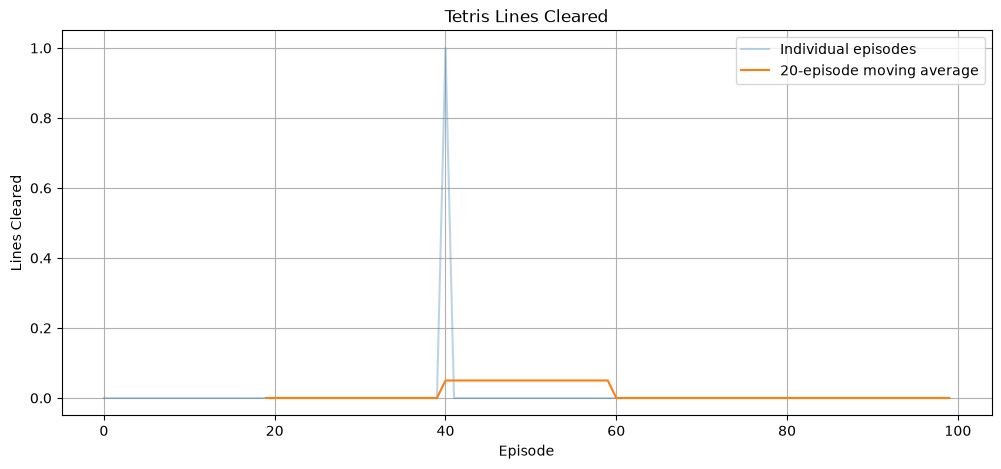

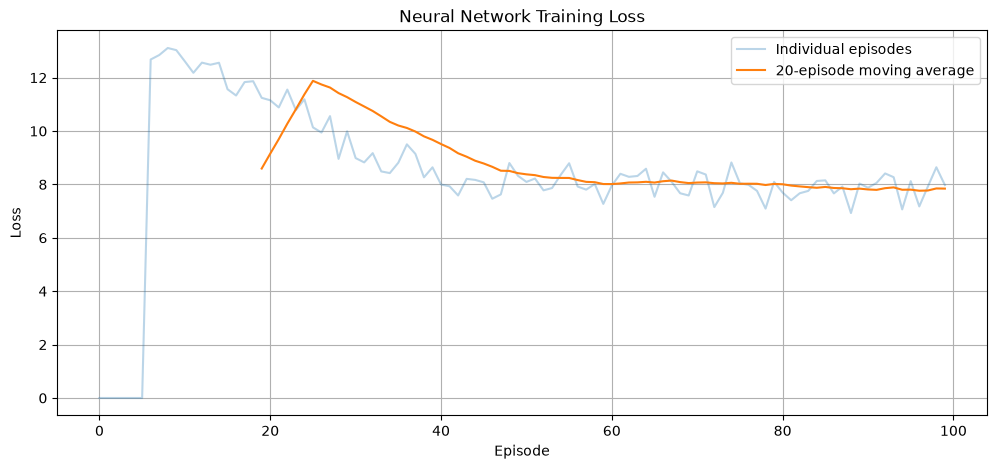

In [13]:
import numpy as np

env = TetrisEnv()
agent = DQNAgent()

episodes = 100
max_pieces = 1000
train_freq = 4  # ONLY TRAIN EVERY 4 STEPS

scores = []
pieces_history = []
lines_history = []
loss_history = []

global_step = 0  # track total steps across all episodes

for episode in range(episodes):
    state = env.reset()
    total_reward = 0
    losses = []
    done = False

    for step in range(max_pieces):
        valid_actions = env.valid_actions()
        action = agent.select_action(state, valid_actions)
        next_state, reward, done = env.step(action)
        truncated = (step == max_pieces - 1)
        terminal = done or truncated

        if terminal:
            next_mask = np.zeros(40, dtype=bool)
        else:
            next_mask = env.valid_actions()

        agent.remember(state, action, reward, next_state, terminal, next_mask)
        
        global_step += 1
        if global_step % train_freq == 0:
            loss = agent.train_step()
            if loss is not None:
                losses.append(loss)

        state = next_state
        total_reward += reward

        if terminal:
            break

    agent.decay_epsilon()
    scores.append(total_reward)
    pieces_history.append(env.pieces_placed)
    lines_history.append(env.rows_cleared)
    loss_history.append(np.mean(losses) if losses else 0)

    print(
        f"Episode: {episode + 1}/{episodes} | "
        f"Pieces: {env.pieces_placed} | "
        f"Lines: {env.rows_cleared} | "
        f"Reward: {total_reward:.2f} | "
        f"Epsilon: {agent.epsilon:.3f}"
    )

def plot_training(history, title, ylabel):
    plt.figure(figsize=(12, 5))
    plt.plot(history, alpha=0.3, label="Individual episodes")

    if len(history) >= 20:
        moving_avg = np.convolve(history, np.ones(20) / 20, mode="valid")
        plt.plot(range(19, len(history)), moving_avg, label="20-episode moving average")

    plt.title(title)
    plt.xlabel("Episode")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid()
    plt.show()

plot_training(scores, "DQN Training Rewards", "Total Reward")
plot_training(pieces_history, "Tetris Survival", "Pieces Placed")
plot_training(lines_history, "Tetris Lines Cleared", "Lines Cleared")
plot_training(loss_history,"Neural Network Training Loss", "Loss")

##### 6. Fine Tune the Model

With the select model descibe the steps taken to acheve the best rusults possiable 

In [14]:
torch.save(agent.policy_net.state_dict(), "dqn_tetris.pth")
print("model saved")

model saved


# 7. Present
In a customer faceing Document provide summery of finding and detail approach taken



# 8. Launch the Model System
Define your production run code, This should be self susficent and require only your model pramaters 


In [16]:
import sys
sys.path.insert(0, "src")

from game import Game

game = Game("student")
pieces, rows = game.run_no_visual()

print("Pieces placed:", pieces)
print("Rows cleared:", rows)

IN Play i : 1 y: 0
best_x 7 best_piece <piece.Piece object at 0x7f744d7b4920>
1 0
IN Play i : 1 y: 0
best_x 1 best_piece <piece.Piece object at 0x7f744d7e9e50>
2 0
IN Play i : 1 y: 2
best_x 0 best_piece <piece.Piece object at 0x7f744d63de20>
3 0
IN Play i : 1 y: 5
best_x 1 best_piece <piece.Piece object at 0x7f744d7b4920>
4 0
IN Play i : 1 y: 8
best_x 1 best_piece <piece.Piece object at 0x7f744d63e5d0>
5 0
IN Play i : 1 y: 0
best_x 4 best_piece <piece.Piece object at 0x7f744d63e660>
6 0
IN Play i : 1 y: 9
best_x 1 best_piece <piece.Piece object at 0x7f744d7b4920>
7 0
IN Play i : 1 y: 3
best_x 5 best_piece <piece.Piece object at 0x7f744d63e6f0>
8 0
IN Play i : 1 y: 12
best_x 1 best_piece <piece.Piece object at 0x7f744d63e2d0>
9 0
IN Play i : 1 y: 2
best_x 7 best_piece <piece.Piece object at 0x7f744d7b4920>
10 0
IN Play i : 1 y: 8
best_x 3 best_piece <piece.Piece object at 0x7f744d63e7e0>
11 0
IN Play i : 1 y: 14
best_x 0 best_piece <piece.Piece object at 0x7f744d63e900>
12 0
IN Play i :